In [6]:
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


# Replay protection experiment analysis

This notebook reads the runner's raw observations and recomputes metrics rather than using fabricated sample results. Choose an experiment directory generated by `run-local-demo-2.js` in the first code cell. Latencies are runner-observed end-to-end HTTP timings; store latency is reported separately.

In [7]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

experiment_dir = Path('../results/replay-2026-11-11T07-38-20-847Z-cdda86af').resolve()  # Set this to a generated run directory.
metadata = json.loads((experiment_dir / 'metadata.json').read_text())
requests = pd.read_csv(experiment_dir / 'requests.csv')
scenarios = pd.read_csv(experiment_dir / 'scenarios.csv')
summary = pd.read_csv(experiment_dir / 'summary.csv')

required_request_columns = {
    'experiment_id', 'scenario_id', 'method', 'replica_count', 'repetition',
    'phase', 'jti_hash', 'replica_id', 'latency_ms', 'actual_outcome',
    'replay_detected', 'legitimate_request', 'request_start_timestamp',
    'request_end_timestamp', 'store_latency_ms'
}
assert required_request_columns <= set(requests.columns)
assert {'scenario_id', 'status', 'completed_requests'} <= set(scenarios.columns)
assert {'scenario_id', 'latency_mean_ms', 'replay_detection_rate'} <= set(summary.columns)
metadata['experiment_id']

'replay-2026-11-11T07-38-20-847Z-cdda86af'

In [8]:
print('requests:', requests.shape, 'scenarios:', scenarios.shape, 'summary:', summary.shape)
display(pd.DataFrame({
    'requests': requests.isna().sum(),
    'scenarios': scenarios.isna().sum(),
    'summary': summary.isna().sum(),
}).fillna(0).astype(int))
display(scenarios)

requests: (10170, 26) scenarios: (18, 18) summary: (18, 25)


,requests,scenarios,summary
accepted_requests,0,0,0
actual_outcome,0,0,0
completed_requests,0,0,0
concurrency_level,0,0,0
cpu_usage,0,0,18
cross_replica_replay_detection_rate,0,0,9
end_time,0,0,0
error_category,10170,0,0
error_count,0,0,0
error_message,10170,0,0


,experiment_id,scenario_id,method,replica_count,repetition,planned_requests,completed_requests,accepted_requests,rejected_requests,replay_attempts,replay_blocked,legitimate_requests,legitimate_accepted,error_count,status,reason,start_time,end_time
0,replay-2026-11-11T07-38-20-847Z-cdda86af,S1,in-memory,1,1,564,564,405,159,160,159,404,404,0,completed,NaN,2026-11-11T07:38:21.193090221Z,2026-11-11T07:38:23.937667662Z
1,replay-2026-11-11T07-38-20-847Z-cdda86af,S1,in-memory,1,2,564,564,405,159,160,159,404,404,0,completed,NaN,2026-11-11T07:38:23.954353349Z,2026-11-11T07:38:26.609521712Z
2,replay-2026-11-11T07-38-20-847Z-cdda86af,S1,in-memory,1,3,564,564,405,159,160,159,404,404,0,completed,NaN,2026-11-11T07:38:26.624261386Z,2026-11-11T07:38:29.420214487Z
3,replay-2026-11-11T07-38-20-847Z-cdda86af,S2,redis,1,1,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:29.435937424Z,2026-11-11T07:38:32.344259538Z
4,replay-2026-11-11T07-38-20-847Z-cdda86af,S2,redis,1,2,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:32.360661938Z,2026-11-11T07:38:35.052281173Z
5,replay-2026-11-11T07-38-20-847Z-cdda86af,S2,redis,1,3,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:35.067629981Z,2026-11-11T07:38:37.762720600Z
6,replay-2026-11-11T07-38-20-847Z-cdda86af,S3,redis-ttl,1,1,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:37.785950583Z,2026-11-11T07:38:40.608004919Z
7,replay-2026-11-11T07-38-20-847Z-cdda86af,S3,redis-ttl,1,2,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:40.625140775Z,2026-11-11T07:38:43.412891077Z
8,replay-2026-11-11T07-38-20-847Z-cdda86af,S3,redis-ttl,1,3,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:43.434916377Z,2026-11-11T07:38:46.240143816Z
9,replay-2026-11-11T07-38-20-847Z-cdda86af,S4,in-memory,2,1,566,566,409,157,161,157,405,405,0,completed,NaN,2026-11-11T07:38:46.257753932Z,2026-11-11T07:38:49.548763803Z


## Security rates

Replay detection rate is replay rejections divided by replay attempts. In a concurrent batch, `n - 1` requests are replay attempts because one request is the expected first use. Legitimate acceptance rate is accepted legitimate requests divided by legitimate requests.

In [9]:
requests['replay_detected'] = requests['replay_detected'].astype(str).str.lower().eq('true')
requests['legitimate_request'] = requests['legitimate_request'].astype(str).str.lower().eq('true')
security_rows = []
keys = ['scenario_id', 'method', 'replica_count', 'repetition']
for key, group in requests.groupby(keys, dropna=False):
    replay = group[group.phase == 'replay']
    concurrent = group[group.phase == 'concurrent_replay']
    # Exclude one expected first-use request per concurrent jti from the replay denominator.
    concurrent_replays = int(concurrent.groupby('jti_hash').size().sub(1).clip(lower=0).sum())
    replay_attempts = len(replay) + concurrent_replays
    concurrent_replay_rows = concurrent[~concurrent.legitimate_request]
    replay_blocked = int(replay.replay_detected.sum() + concurrent_replay_rows.replay_detected.sum())
    legitimate = group[group.legitimate_request]
    legitimate_accepted = int((legitimate.actual_outcome == 'accepted').sum())
    security_rows.append({
        **dict(zip(keys, key)),
        'replay_detection_rate': replay_blocked / replay_attempts if replay_attempts else np.nan,
        'legitimate_request_acceptance_rate': legitimate_accepted / len(legitimate) if len(legitimate) else np.nan,
        'false_acceptance_count': int((replay.actual_outcome == 'accepted').sum()) + max(0, int((concurrent.actual_outcome == 'accepted').sum()) - concurrent.jti_hash.nunique()),
        'cross_replica_replay_detection_rate': replay.loc[replay.replay_context == 'cross_replica', 'replay_detected'].mean(),
    })
security = pd.DataFrame(security_rows)
display(security)

,scenario_id,method,replica_count,repetition,replay_detection_rate,legitimate_request_acceptance_rate,false_acceptance_count,cross_replica_replay_detection_rate
0,S1,in-memory,1,1,0.993750,1.0,1,NaN
1,S1,in-memory,1,2,0.993750,1.0,1,NaN
2,S1,in-memory,1,3,0.993750,1.0,1,NaN
3,S2,redis,1,1,1.000000,1.0,0,NaN
4,S2,redis,1,2,1.000000,1.0,0,NaN
5,S2,redis,1,3,1.000000,1.0,0,NaN
6,S3,redis-ttl,1,1,1.000000,1.0,0,NaN
7,S3,redis-ttl,1,2,1.000000,1.0,0,NaN
8,S3,redis-ttl,1,3,1.000000,1.0,0,NaN
9,S4,in-memory,2,1,0.975155,1.0,4,0.0


## Latency and throughput

The latency distribution uses only raw `performance` requests. Mean, median, sample standard deviation (`ddof=1`), p95, and p99 use the request observations directly. Throughput is completed performance requests divided by the span between the earliest request start and latest request end within each concurrency window.

In [10]:
requests['latency_ms'] = pd.to_numeric(requests['latency_ms'], errors='coerce')
requests['store_latency_ms'] = pd.to_numeric(requests['store_latency_ms'], errors='coerce')
requests['request_start_timestamp'] = pd.to_datetime(requests.request_start_timestamp, utc=True, errors='coerce')
requests['request_end_timestamp'] = pd.to_datetime(requests.request_end_timestamp, utc=True, errors='coerce')
performance = requests[requests.phase == 'performance'].copy()
latency_metrics = performance.groupby(keys, dropna=False).latency_ms.agg(
    latency_mean_ms='mean', latency_median_ms='median', latency_std_ms='std'
).reset_index()
percentiles = performance.groupby(keys, dropna=False).latency_ms.agg(
    latency_p95_ms=lambda values: values.quantile(.95, interpolation='linear'),
    latency_p99_ms=lambda values: values.quantile(.99, interpolation='linear'),
).reset_index()
latency_metrics = latency_metrics.merge(percentiles, on=keys, how='left')
display(latency_metrics)

throughput_rows = []
for group_key, group in performance.groupby(keys + ['concurrency_level'], dropna=False):
    group = group.dropna(subset=['request_start_timestamp', 'request_end_timestamp'])
    duration = (group.request_end_timestamp.max() - group.request_start_timestamp.min()).total_seconds() if len(group) else np.nan
    throughput_rows.append({
        **dict(zip(keys + ['concurrency_level'], group_key)),
        'completed_requests': len(group),
        'measurement_duration_seconds': duration,
        'throughput_rps': len(group) / duration if duration and duration > 0 else np.nan,
    })
throughput = pd.DataFrame(throughput_rows)
display(throughput)

,scenario_id,method,replica_count,repetition,latency_mean_ms,latency_median_ms,latency_std_ms,latency_p95_ms,latency_p99_ms
0,S1,in-memory,1,1,33.875476,16.788061,34.404723,89.916068,97.062989
1,S1,in-memory,1,2,33.373050,17.487439,33.561290,86.093079,89.449822
2,S1,in-memory,1,3,37.201942,17.328336,38.535488,97.929826,102.178931
3,S2,redis,1,1,48.557715,19.971024,53.934281,140.851173,142.459406
4,S2,redis,1,2,34.685243,17.303378,35.353393,92.769201,95.548321
5,S2,redis,1,3,36.945177,18.082017,38.496320,104.722432,107.847178
6,S3,redis-ttl,1,1,37.828379,19.351378,38.509616,101.238071,102.972991
7,S3,redis-ttl,1,2,38.154497,19.191128,38.842028,100.008217,105.266886
8,S3,redis-ttl,1,3,45.735715,18.448088,49.721077,124.164125,127.190912
9,S4,in-memory,2,1,39.098040,18.548364,40.190991,106.341733,108.717026


,scenario_id,method,replica_count,repetition,concurrency_level,completed_requests,measurement_duration_seconds,throughput_rps
0,S1,in-memory,1,1,1,100,0.401058,249.340713
1,S1,in-memory,1,1,10,100,0.218646,457.360778
2,S1,in-memory,1,1,50,100,0.198491,503.800175
3,S1,in-memory,1,2,1,100,0.377699,264.761374
4,S1,in-memory,1,2,10,100,0.222123,450.200526
5,S1,in-memory,1,2,50,100,0.189218,528.490103
6,S1,in-memory,1,3,1,100,0.426701,234.356088
7,S1,in-memory,1,3,10,100,0.218060,458.589205
8,S1,in-memory,1,3,50,100,0.212199,471.255358
9,S2,redis,1,1,1,100,0.386879,258.478997


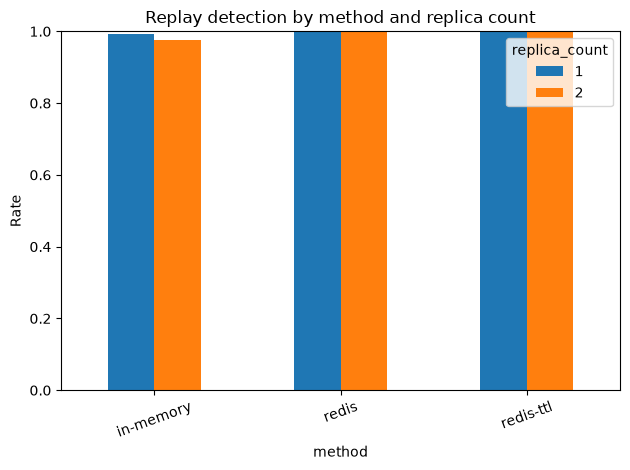

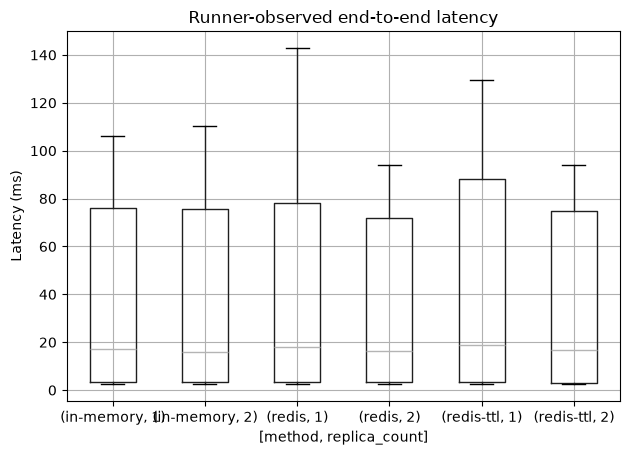

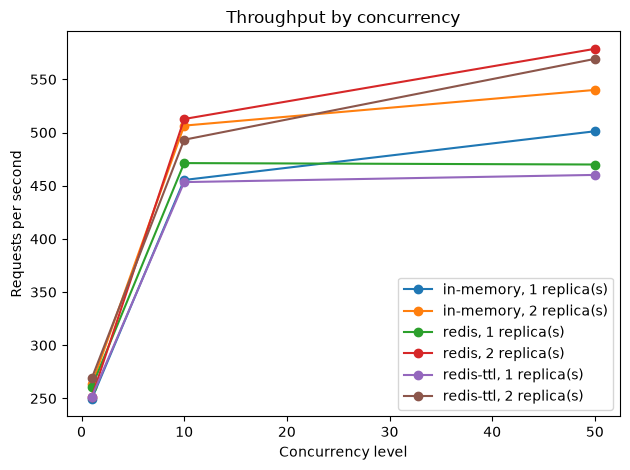

,method,replica_count,replay_detection_rate,legitimate_request_acceptance_rate
0,in-memory,1,0.993750,1.0
1,in-memory,2,0.975155,1.0
2,redis,1,1.000000,1.0
3,redis,2,1.000000,1.0
4,redis-ttl,1,1.000000,1.0
5,redis-ttl,2,1.000000,1.0


In [11]:
analysis_dir = experiment_dir / 'analysis'
analysis_dir.mkdir(exist_ok=True)
security.to_csv(analysis_dir / 'notebook_security_metrics.csv', index=False)
latency_metrics.to_csv(analysis_dir / 'notebook_latency_metrics.csv', index=False)
throughput.to_csv(analysis_dir / 'notebook_throughput.csv', index=False)

comparison = (security.groupby(['method', 'replica_count'], as_index=False).agg(
    replay_detection_rate=('replay_detection_rate', 'mean'),
    legitimate_request_acceptance_rate=('legitimate_request_acceptance_rate', 'mean'),
) if not security.empty else pd.DataFrame())
if not comparison.empty:
    comparison.pivot(index='method', columns='replica_count', values='replay_detection_rate').plot(
        kind='bar', ylim=(0, 1), rot=20, title='Replay detection by method and replica count'
    )
    plt.ylabel('Rate')
    plt.tight_layout()
    plt.savefig(analysis_dir / 'notebook_security_rates.png', dpi=150)
    plt.show()

if not performance.empty:
    performance.boxplot(column='latency_ms', by=['method', 'replica_count'])
    plt.suptitle('')
    plt.title('Runner-observed end-to-end latency')
    plt.ylabel('Latency (ms)')
    plt.tight_layout()
    plt.savefig(analysis_dir / 'notebook_latency.png', dpi=150)
    plt.show()

if not throughput.empty:
    for (method, replica_count), group in throughput.groupby(['method', 'replica_count']):
        group.groupby('concurrency_level').throughput_rps.mean().sort_index().plot(
            marker='o', label=f'{method}, {replica_count} replica(s)'
        )
    plt.title('Throughput by concurrency')
    plt.xlabel('Concurrency level')
    plt.ylabel('Requests per second')
    plt.legend()
    plt.tight_layout()
    plt.savefig(analysis_dir / 'notebook_throughput.png', dpi=150)
    plt.show()
display(comparison)